In [1]:
import yfinance as yf

def get_bougies():
    df = yf.Ticker("MNQ=F").history(period="2d", interval="1m")
    return df

bougies = get_bougies()
bougies.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,
2026-10-13 05:48:00-04:00,30742.50,30745.00,30737.50,30739.00,463,0.0,0.0
2026-10-13 05:49:00-04:00,30739.50,30744.50,30739.50,30741.25,314,0.0,0.0
2026-10-13 05:50:00-04:00,30742.25,30743.25,30739.25,30740.50,481,0.0,0.0
2026-10-13 05:51:00-04:00,30740.00,30743.00,30738.75,30741.25,279,0.0,0.0
2026-10-13 05:52:00-04:00,30741.50,30746.25,30737.50,30740.00,0,0.0,0.0


In [2]:
def preparer(df):
    df = df.copy()
    df.index = df.index.tz_convert("America/New_York").tz_localize(None)
    df = df.reset_index()
    df.columns = [c.lower() for c in df.columns]
    df = df.rename(columns={"datetime": "time"})
    return df[["time", "open", "high", "low", "close", "volume"]]

chart_df = preparer(bougies)
chart_df.tail()

,time,open,high,low,close,volume
1718,2026-10-13 05:48:00,30742.50,30745.00,30737.50,30739.00,463
1719,2026-10-13 05:49:00,30739.50,30744.50,30739.50,30741.25,314
1720,2026-10-13 05:50:00,30742.25,30743.25,30739.25,30740.50,481
1721,2026-10-13 05:51:00,30740.00,30743.00,30738.75,30741.25,279
1722,2026-10-13 05:52:00,30741.50,30746.25,30737.50,30740.00,0


In [3]:
from lightweight_charts import JupyterChart

chart = JupyterChart(width=1000, height=550)

# Style sombre façon Vexity
chart.layout(background_color="#0b0e14", text_color="#8a93a6", font_size=12)
chart.grid(vert_enabled=False, horz_enabled=True, color="#1a1f2b")
chart.candle_style(
    up_color="#26a69a", down_color="#ef5350",
    wick_up_color="#26a69a", wick_down_color="#ef5350",
    border_up_color="#26a69a", border_down_color="#ef5350",
)
chart.volume_config(up_color="rgba(38,166,154,0.25)", down_color="rgba(239,83,80,0.25)")

chart.set(chart_df)
chart.load()

In [4]:
def generer_ligne(niveaux):
    morceaux = []
    for nom, prix in niveaux.items():
        morceaux.append(f"{nom}={prix:.2f}")
    return ";".join(morceaux)


niveaux = {
    "call_wall": 30900,
    "put_wall": 30550,
    "gamma_flip": 30700,
    "hvl": 30650,
    "major_put": 30500,
}

print(generer_ligne(niveaux))

call_wall=30900.00;put_wall=30550.00;gamma_flip=30700.00;hvl=30650.00;major_put=30500.00


In [5]:
def convertir_en_nq(strike, prix_source, prix_nq):
    ratio = prix_nq / prix_source
    return round(strike * ratio * 4) / 4

In [6]:
print(convertir_en_nq(720, prix_source=713, prix_nq=30700))

31001.5


In [7]:
import yfinance as yf
import pandas as pd

def get_chaine(ticker="QQQ", nb_echeances=3):
    t = yf.Ticker(ticker)
    spot = t.history(period="1d")["Close"].iloc[-1]

    morceaux = []
    for echeance in t.options[:nb_echeances]:
        chaine = t.option_chain(echeance)
        morceaux.append(chaine.calls.assign(type="call", expiration=echeance))
        morceaux.append(chaine.puts.assign(type="put", expiration=echeance))

    df = pd.concat(morceaux)
    df = df[["type", "expiration", "strike", "openInterest", "impliedVolatility", "volume"]]
    return spot, df.fillna(0)


spot_qqq, options = get_chaine()
print("Prix du QQQ :", round(spot_qqq, 2))
print(len(options), "options récupérées")
options.head()

Prix du QQQ : 746.04
688 options récupérées


,type,expiration,strike,openInterest,impliedVolatility,volume
0,call,2026-10-13,525.0,0.0,0.00001,17.0
1,call,2026-10-13,530.0,0.0,0.00001,11.0
2,call,2026-10-13,680.0,0.0,0.00001,1.0
3,call,2026-10-13,685.0,1.0,0.00001,0.0
4,call,2026-10-13,690.0,0.0,0.00001,41.0


In [8]:
import numpy as np
from scipy.stats import norm

def gamma_bs(S, K, T, sigma, r=0.04):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return norm.pdf(d1) / (S * sigma * np.sqrt(T))

In [9]:
print(gamma_bs(S=713, K=713, T=7/365, sigma=0.20))
print(gamma_bs(S=713, K=750, T=7/365, sigma=0.20))

0.020184274807504496
0.00410631972691009


In [10]:
from datetime import datetime
from zoneinfo import ZoneInfo

NY = ZoneInfo("America/New_York")

def temps_restant(echeance):
    fin = datetime.strptime(echeance, "%Y-%m-%d").replace(hour=16, tzinfo=NY)
    secondes = (fin - datetime.now(NY)).total_seconds()
    return max(secondes, 3600) / (365 * 24 * 3600)


opts = options[(options["openInterest"] > 0) & (options["impliedVolatility"] > 0.01)].copy()
opts["T"] = opts["expiration"].apply(temps_restant)
opts["gamma"] = gamma_bs(spot_qqq, opts["strike"], opts["T"], opts["impliedVolatility"])
opts.head()

,type,expiration,strike,openInterest,impliedVolatility,volume,T,gamma
53,call,2026-10-13,754.0,3203.0,0.062509,8392.0,0.00105,3.217210e-07
54,call,2026-10-13,755.0,6142.0,0.062509,10135.0,0.00105,8.534592e-09
56,call,2026-10-13,757.0,1961.0,0.062509,4149.0,0.00105,1.693040e-12
59,call,2026-10-13,760.0,4598.0,0.062509,4562.0,0.00105,2.046410e-19
64,call,2026-10-13,765.0,2453.0,0.125009,3517.0,0.00105,6.547662e-10


In [11]:
opts["gex"] = opts["gamma"] * opts["openInterest"] * 100 * spot_qqq**2 * 0.01
opts.loc[opts["type"] == "put", "gex"] *= -1

gex_par_strike = opts.groupby("strike")["gex"].sum()

In [12]:
calls_gex = opts[opts["type"] == "call"].groupby("strike")["gex"].sum()
puts_gex = opts[opts["type"] == "put"].groupby("strike")["gex"].sum()
volume_par_strike = opts.groupby("strike")["volume"].sum()

call_wall = calls_gex.idxmax()
put_wall = puts_gex.idxmin()
hvl = volume_par_strike.idxmax()

print("Call wall :", call_wall)
print("Put wall  :", put_wall)
print("HVL       :", hvl)

Call wall : 762.0
Put wall  : 730.0
HVL       : 755.0


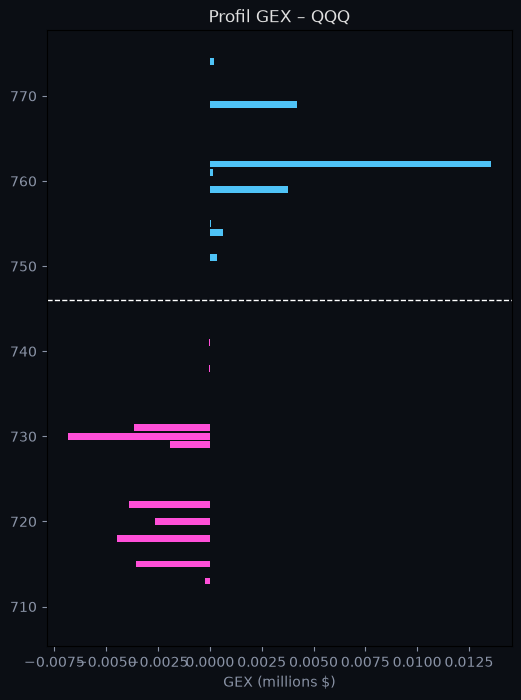

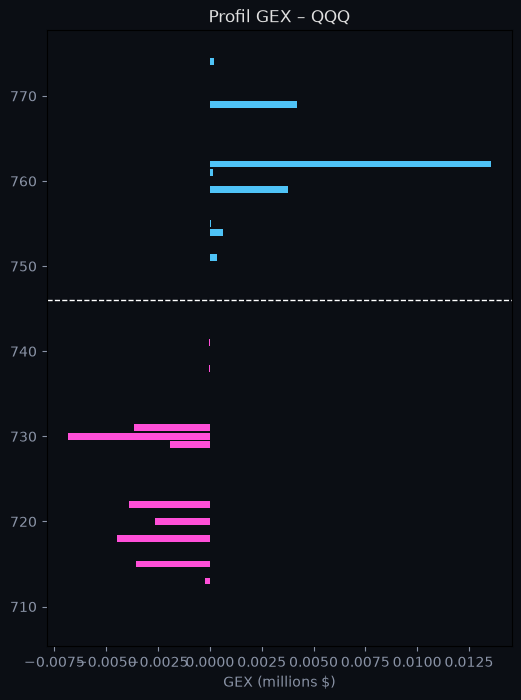

In [14]:
%matplotlib inline
import matplotlib.pyplot as plt

zone = gex_par_strike[(gex_par_strike.index > spot_qqq * 0.95) & (gex_par_strike.index < spot_qqq * 1.05)]

plt.figure(figsize=(6, 8), facecolor="#0b0e14")
ax = plt.gca()
ax.set_facecolor("#0b0e14")
ax.barh(zone.index, zone.values / 1e6, color=["#4fc3f7" if v > 0 else "#ff4fd8" for v in zone.values], height=0.8)
ax.axhline(spot_qqq, color="#ffffff", linestyle="--", linewidth=1)
ax.set_xlabel("GEX (millions $)", color="#8a93a6")
ax.tick_params(colors="#8a93a6")
plt.title("Profil GEX – QQQ", color="#e0e0e0")
plt.show()

In [15]:
def gex_total(prix):
    g = gamma_bs(prix, opts["strike"], opts["T"], opts["impliedVolatility"])
    gex = g * opts["openInterest"] * 100 * prix**2 * 0.01
    signe = np.where(opts["type"] == "call", 1, -1)
    return (gex * signe).sum()


grille = np.linspace(spot_qqq * 0.95, spot_qqq * 1.05, 200)
totaux = np.array([gex_total(p) for p in grille])

changements = np.where(np.diff(np.sign(totaux)) != 0)[0]
gamma_flip = grille[changements[0]] if len(changements) > 0 else None
print("Gamma flip :", gamma_flip)

Gamma flip : 745.8525307966836


In [16]:
prix_nq = yf.Ticker("MNQ=F").history(period="1d", interval="1m")["Close"].iloc[-1]

niveaux_qqq = {
    "call_wall": call_wall,
    "put_wall": put_wall,
    "hvl": hvl,
}
if gamma_flip is not None:
    niveaux_qqq["gamma_flip"] = gamma_flip

niveaux_nq = {nom: convertir_en_nq(v, spot_qqq, prix_nq) for nom, v in niveaux_qqq.items()}

print("QQQ :", round(spot_qqq, 2), "| NQ :", prix_nq)
print(niveaux_nq)
print()
print(generer_ligne(niveaux_nq))

QQQ : 746.04 | NQ : 30731.75
{'call_wall': 31389.25, 'put_wall': 30071.0, 'hvl': 31100.75, 'gamma_flip': 30724.0}

call_wall=31389.25;put_wall=30071.00;hvl=31100.75;gamma_flip=30724.00


In [17]:
import subprocess

ligne = generer_ligne(niveaux_nq)
subprocess.run("pbcopy", input=ligne.encode())
print("✅ Ligne copiée dans le presse-papiers")

✅ Ligne copiée dans le presse-papiers
